# California Home Price Prediction
## Week 3: Data Preprocessing

This notebook prepares the sales data for modeling. It cleans the data, compares several training windows, keeps April 2026 as the test set, and exports a cleaned CSV.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw" / "California"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

START_MONTH, TEST_MONTH = "202502", "202604"
RANDOM_STATE = 42
print(f"Project folder: {PROJECT_ROOT}")
print(f"Held-out test month: {TEST_MONTH}")

Project folder: C:\Users\jackyfirst\Downloads\IDX Exchange DS
Held-out test month: 202604


## 1. Load the data

Load the 15 monthly files and keep the target, property details, location, and date fields.

In [2]:
columns = [
    "ListingKey", "CloseDate", "ClosePrice", "PropertyType", "PropertySubType",
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
    "YearBuilt", "City", "CountyOrParish"
]
expected_months = pd.period_range(START_MONTH, TEST_MONTH, freq="M").strftime("%Y%m")
files = [RAW_DIR / f"CRMLSSold{month}.csv" for month in expected_months]
missing_files = [path.name for path in files if not path.exists()]
assert not missing_files, f"Missing files: {missing_files}"

frames = []
for path in files:
    monthly = pd.read_csv(path, usecols=columns, low_memory=False)
    monthly["SourceMonth"] = path.stem[-6:]
    frames.append(monthly)
raw_df = pd.concat(frames, ignore_index=True)
print(f"Files loaded: {len(files)}")
print(f"Raw rows: {len(raw_df):,}")
display(raw_df.head())

Files loaded: 15
Raw rows: 321,972


,ListingKey,CloseDate,ClosePrice,PropertyType,LivingArea,CountyOrParish,PropertySubType,YearBuilt,BathroomsTotalInteger,City,BedroomsTotal,LotSizeSquareFeet,SourceMonth
0,526199946,2025-02-21,"35,000.00",Land,NaN,San Bernardino,NaN,NaN,NaN,Apple Valley,NaN,"28,000.00",202502
1,525585060,2025-02-14,"625,000.00",Land,NaN,Riverside,NaN,NaN,NaN,Moreno Valley,NaN,"39,640.00",202502
2,497696903,2025-02-11,"875,000.00",Residential,"2,340.00",San Diego,SingleFamilyResidence,"2,021.00",4.00,La Mesa,4.00,NaN,202502
3,497696407,2025-02-14,"875,000.00",Residential,"2,165.00",San Diego,SingleFamilyResidence,"2,021.00",4.00,La Mesa,5.00,NaN,202502
4,486616176,2025-02-18,"849,000.00",Residential,"2,158.00",San Diego,SingleFamilyResidence,"2,021.00",3.00,La Mesa,4.00,NaN,202502


## 2. Clean the data

Keep residential single-family homes, remove invalid target values and duplicate listings, and change impossible feature values to missing. Raw source files are not modified.

In [3]:
segment = (
    raw_df["PropertyType"].astype("string").str.strip().eq("Residential")
    & raw_df["PropertySubType"].astype("string").str.strip().eq("SingleFamilyResidence")
)
df = raw_df.loc[segment].copy()
rows_after_segment = len(df)

numeric_features = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt"]
categorical_features = ["City", "CountyOrParish"]
for column in ["ClosePrice", *numeric_features]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
df["CloseDate"] = pd.to_datetime(df["CloseDate"], errors="coerce")

invalid_target = df["ClosePrice"].isna() | (df["ClosePrice"] <= 0)
df = df.loc[~invalid_target].copy()
df = df.sort_values(["CloseDate", "SourceMonth"]).drop_duplicates("ListingKey", keep="last")

invalid_counts = {}
rules = {
    "LivingArea": (df["LivingArea"] <= 0),
    "BedroomsTotal": (df["BedroomsTotal"] < 0),
    "BathroomsTotalInteger": (df["BathroomsTotalInteger"] < 0),
    "LotSizeSquareFeet": (df["LotSizeSquareFeet"] <= 0),
    "YearBuilt": ((df["YearBuilt"] < 1800) | (df["YearBuilt"] > df["CloseDate"].dt.year)),
}
for column, mask in rules.items():
    invalid_counts[column] = int(mask.fillna(False).sum())
    df.loc[mask.fillna(False), column] = np.nan
for column in categorical_features:
    cleaned = df[column].astype("string").str.strip()
    cleaned = cleaned.mask(cleaned.eq("") | cleaned.str.lower().isin(["nan", "none", "unknown"]))
    # Object dtype with np.nan works across both older and newer scikit-learn versions.
    df[column] = cleaned.astype(object).where(cleaned.notna(), np.nan)

quality_summary = pd.DataFrame({
    "stage": ["Raw rows", "Required property segment", "Positive target + unique listing"],
    "rows": [len(raw_df), rows_after_segment, len(df)]
})
display(quality_summary)
print("Feature values changed to missing:", invalid_counts)
print(f"Unique listing keys: {df['ListingKey'].nunique():,}")

,stage,rows
0,Raw rows,321972
1,Required property segment,161314
2,Positive target + unique listing,161195


Feature values changed to missing: {'LivingArea': 79, 'BedroomsTotal': 0, 'BathroomsTotalInteger': 0, 'LotSizeSquareFeet': 86, 'YearBuilt': 16}
Unique listing keys: 161,195


## 3. Check missing values

Numeric features will use the training median. Missing city or county values will use `Unknown`. The target is never imputed.

In [4]:
model_features = numeric_features + categorical_features
missing_before = pd.DataFrame({
    "missing_rows": df[model_features].isna().sum(),
    "missing_percent": df[model_features].isna().mean().mul(100)
}).sort_values("missing_percent", ascending=False)
display(missing_before)

,missing_rows,missing_percent
LotSizeSquareFeet,2884,1.79
LivingArea,164,0.10
YearBuilt,122,0.08
City,72,0.04
BathroomsTotalInteger,19,0.01
BedroomsTotal,0,0.00
CountyOrParish,0,0.00


## 4. Create a time-based split

April 2026 is the test set. Compare several training windows using sample size, city coverage, and the difference in median price. Twelve months is a practical starting point because it covers a full year and keeps the data recent.

In [5]:
test_mask = df["SourceMonth"].eq(TEST_MONTH)
test_df = df.loc[test_mask].copy()
pre_test = df.loc[~test_mask & (df["SourceMonth"] < TEST_MONTH)].copy()
available_train_months = sorted(pre_test["SourceMonth"].unique())
candidate_windows = [x for x in [3, 6, 9, 12, 14] if x <= len(available_train_months)]

window_rows = []
test_cities = set(test_df["City"].dropna())
for months in candidate_windows:
    selected = available_train_months[-months:]
    candidate = pre_test[pre_test["SourceMonth"].isin(selected)]
    covered = test_df["City"].isin(set(candidate["City"].dropna())).mean() * 100
    median_shift = abs(candidate["ClosePrice"].median() / test_df["ClosePrice"].median() - 1) * 100
    window_rows.append({
        "training_months_X": months,
        "start_month": selected[0],
        "end_month": selected[-1],
        "training_rows": len(candidate),
        "test_city_coverage_percent": covered,
        "median_price_shift_percent": median_shift,
    })
window_comparison = pd.DataFrame(window_rows)
display(window_comparison)

SELECTED_X = min(12, len(available_train_months))
selected_months = available_train_months[-SELECTED_X:]
train_df = pre_test[pre_test["SourceMonth"].isin(selected_months)].copy()
assert set(train_df["ListingKey"]).isdisjoint(set(test_df["ListingKey"]))
print(f"Selected X: {SELECTED_X} months ({selected_months[0]}–{selected_months[-1]})")
print(f"Train rows: {len(train_df):,}; test rows: {len(test_df):,}")

,training_months_X,start_month,end_month,training_rows,test_city_coverage_percent,median_price_shift_percent
0,3,202601,202603,27198,99.46,4.99
1,6,202510,202603,59387,99.76,4.99
2,9,202507,202603,94389,99.80,4.45
3,12,202504,202603,129716,99.86,3.74
4,14,202502,202603,149164,99.87,3.47


Selected X: 12 months (202504–202603)
Train rows: 129,716; test rows: 12,031


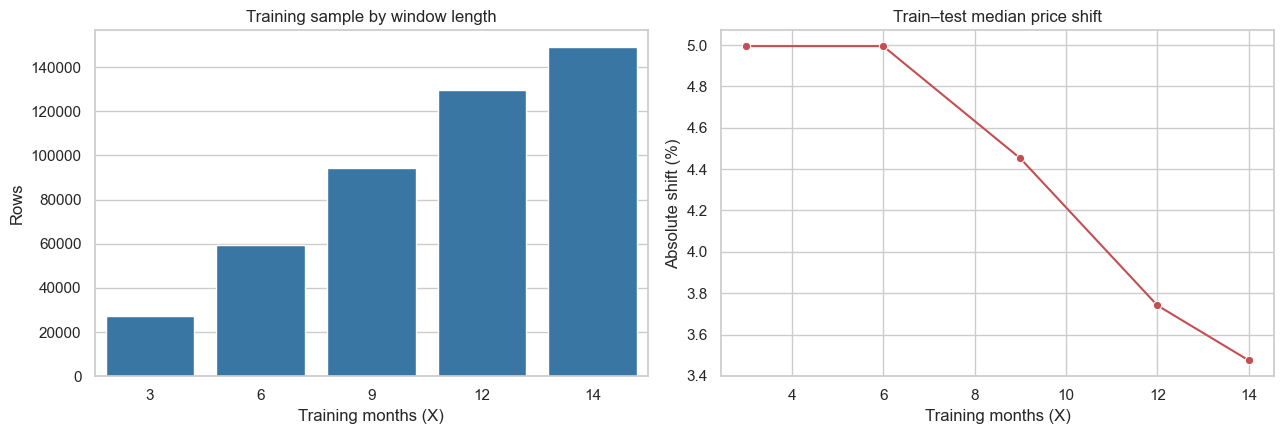

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=window_comparison, x="training_months_X", y="training_rows", ax=axes[0], color="#2878B5")
axes[0].set_title("Training sample by window length")
axes[0].set_xlabel("Training months (X)")
axes[0].set_ylabel("Rows")
sns.lineplot(data=window_comparison, x="training_months_X", y="median_price_shift_percent", marker="o", ax=axes[1], color="#C44E52")
axes[1].set_title("Train–test median price shift")
axes[1].set_xlabel("Training months (X)")
axes[1].set_ylabel("Absolute shift (%)")
plt.tight_layout()
plt.show()

## 5. Prepare features for modeling

Fill and scale numeric features, and one-hot encode city and county. Fit every preprocessing step on the training data only, then apply it to the test set.

In [7]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=True)),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

X_train = preprocessor.fit_transform(train_df[model_features])
X_test = preprocessor.transform(test_df[model_features])
y_train = train_df["ClosePrice"].to_numpy()
y_test = test_df["ClosePrice"].to_numpy()
feature_names = preprocessor.get_feature_names_out()

print(f"Encoded training shape: {X_train.shape}")
print(f"Encoded test shape: {X_test.shape}")
print(f"Output features: {len(feature_names):,}")
print("First 15 output features:")
print(feature_names[:15])
assert X_train.shape[1] == X_test.shape[1]
assert not np.isnan(X_train.data if hasattr(X_train, "data") else X_train).any()
assert not np.isnan(X_test.data if hasattr(X_test, "data") else X_test).any()

Encoded training shape: (129716, 1055)
Encoded test shape: (12031, 1055)
Output features: 1,055
First 15 output features:
['numeric__LivingArea' 'numeric__BedroomsTotal'
 'numeric__BathroomsTotalInteger' 'numeric__LotSizeSquareFeet'
 'numeric__YearBuilt' 'categorical__City_29 Palms'
 'categorical__City_Acton' 'categorical__City_Adelanto'
 'categorical__City_Agoura' 'categorical__City_Agoura Hills'
 'categorical__City_Agua Dulce' 'categorical__City_Aguanga'
 'categorical__City_Ahwahnee' 'categorical__City_Alameda'
 'categorical__City_Alamo']


## 6. Export the cleaned data

Save a readable CSV with a `DataSplit` column. The one-hot encoding stays in the modeling pipeline instead of creating a very wide CSV.

In [8]:
train_numeric_medians = train_df[numeric_features].median()
export_df = pd.concat([train_df, test_df], ignore_index=True)
export_df["DataSplit"] = np.where(export_df["SourceMonth"].eq(TEST_MONTH), "test", "train")
export_df[numeric_features] = export_df[numeric_features].fillna(train_numeric_medians)
export_df[categorical_features] = export_df[categorical_features].fillna("Unknown")
export_columns = [
    "ListingKey", "CloseDate", "SourceMonth", "DataSplit", "ClosePrice",
    *numeric_features, *categorical_features
]
export_df = export_df[export_columns].sort_values(["SourceMonth", "ListingKey"])

output_path = PROCESSED_DIR / "california_sfr_cleaned_week3.csv"
export_df.to_csv(output_path, index=False, date_format="%Y-%m-%d")

manifest = {
    "source_period": [START_MONTH, TEST_MONTH],
    "property_filter": {"PropertyType": "Residential", "PropertySubType": "SingleFamilyResidence"},
    "selected_training_months_X": SELECTED_X,
    "training_period": [selected_months[0], selected_months[-1]],
    "test_month": TEST_MONTH,
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "numeric_imputation": "training median",
    "categorical_imputation": "Unknown",
    "encoding": "one-hot, unknown categories ignored",
    "scaling": "standardization fitted on training data only",
    "features": model_features,
}
(PROCESSED_DIR / "week3_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")

print(f"Saved: {output_path}")
print(f"Rows exported: {len(export_df):,}")
print(f"File size: {output_path.stat().st_size / 1_000_000:.1f} MB")
display(export_df.head())

Saved: C:\Users\jackyfirst\Downloads\IDX Exchange DS\data\processed\california_sfr_cleaned_week3.csv
Rows exported: 141,747
File size: 13.6 MB


,ListingKey,CloseDate,SourceMonth,DataSplit,ClosePrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,City,CountyOrParish
6526,1028488233,2025-04-16,202504,train,"725,000.00","1,008.00",3.00,1.00,"6,659.00","1,947.00",North Hollywood,Los Angeles
11053,1030704958,2025-04-28,202504,train,"2,325,000.00","2,815.00",4.00,3.00,"19,600.00","1,978.00",Alamo,Contra Costa
8770,1035482493,2025-04-22,202504,train,"790,000.00","1,726.00",3.00,3.00,"2,389.00","2,023.00",Pomona,Los Angeles
8769,1035483136,2025-04-22,202504,train,"770,000.00","1,726.00",3.00,3.00,"2,505.00","2,023.00",Pomona,Los Angeles
2764,1037648737,2025-04-07,202504,train,"5,625,000.00","5,423.00",5.00,7.00,"2,831,400.00","1,979.00",Solvang,Santa Barbara


## Conclusion

- Cleaned and deduplicated the required property data.
- Used 12 recent months for training: 129,716 rows.
- Kept April 2026 for testing: 12,031 rows.
- Created 1,055 model-ready features with no missing values.
- Exported 141,747 cleaned rows.

**Next:** train the Week 4 linear regression model and use time-based validation to confirm the best training window.